<a href="https://colab.research.google.com/github/asianmouse/Data-201-Project-1/blob/main/Data-201-Project-1/project_one.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Part one**

1. Each row is a patient, with the columns being the variables that describe them like sex, blood pressure, cholesterol and more. The response variable is target. Where one is where they do have heart disease and o is that they don't have hear disease.
2. For the predictors, I will use age, sex, chol, thalach, and cp.
3. The dataset has 1025 rows but 723 of them are duplicates. 526 of them has the heart disease while 499 doesn't have it, so it is balance.
4. The false positive in this case is that the model predicts tbat  heart disease is present but in reality they don't have it( so it is a false warning). False neegative is the invert of that, so the model predicts that they don't have heart disease but they really do.
5. False negatives is worse for this dataset so false positives is just a  false warning so they won't suffer. But for the false negatives, if it gets missed then they won't get treated for it, so it could lead into a heart attack.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

file_path = "/content/drive/MyDrive/Data_201/Datasets/heart.csv"

Mounted at /content/drive


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import KFold

from sklearn.model_selection import (
    train_test_split, cross_val_score, StratifiedKFold
)

from sklearn.preprocessing import (
    OneHotEncoder, StandardScaler, MinMaxScaler,
    RobustScaler, Normalizer, KBinsDiscretizer,
    FunctionTransformer
)
from sklearn.model_selection import (train_test_split, cross_val_score, cross_validate,
                                     KFold, StratifiedKFold, LeaveOneOut, GridSearchCV)
from sklearn.compose import ColumnTransformer

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, accuracy_score, precision_score,
                             recall_score, f1_score, roc_auc_score, roc_curve, fbeta_score)
from sklearn.metrics import confusion_matrix
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis


In [3]:
 df = pd.read_csv(file_path)

In [4]:
df.shape

(1025, 14)

In [5]:
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0


In [6]:
df.value_counts()

age  sex  cp  trestbps  chol  fbs  restecg  thalach  exang  oldpeak  slope  ca  thal  target
38   1    2   138       175   0    1        173      0      0.0      2      4   2     1         8
40   1    0   152       223   0    1        181      0      0.0      2      0   3     0         4
              110       167   0    0        114      1      2.0      1      0   3     0         4
41   1    1   120       157   0    1        182      0      0.0      2      0   2     1         4
71   0    0   112       149   0    1        125      0      1.6      1      0   2     1         4
                                                                                               ..
41   0    1   105       198   0    1        168      0      0.0      2      1   2     1         3
40   1    3   140       199   0    1        178      1      1.4      2      0   3     1         3
34   0    1   118       210   0    1        192      0      0.7      2      0   2     1         3
77   1    0   125       304   0    0        162      1      0.0      2      3   2     0         3
39   1    2   140       321   0    0        182      0      0.0      2      0   2     1         3
Name: count, Length: 302, dtype: int64

In [7]:
df["target"].value_counts()

,count
target,
1,526
0,499


In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1025 entries, 0 to 1024
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1025 non-null   int64  
 1   sex       1025 non-null   int64  
 2   cp        1025 non-null   int64  
 3   trestbps  1025 non-null   int64  
 4   chol      1025 non-null   int64  
 5   fbs       1025 non-null   int64  
 6   restecg   1025 non-null   int64  
 7   thalach   1025 non-null   int64  
 8   exang     1025 non-null   int64  
 9   oldpeak   1025 non-null   float64
 10  slope     1025 non-null   int64  
 11  ca        1025 non-null   int64  
 12  thal      1025 non-null   int64  
 13  target    1025 non-null   int64  
dtypes: float64(1), int64(13)
memory usage: 112.2 KB


In [9]:
df.isna().sum()

,0
age,0
sex,0
cp,0
trestbps,0
chol,0
fbs,0
restecg,0
thalach,0
exang,0
oldpeak,0


In [10]:
df.duplicated().sum()

np.int64(723)

**Part two**

In [11]:
df["age"].describe()

,age
count,1025.000000
mean,54.434146
std,9.072290
min,29.000000
25%,48.000000
50%,56.000000
75%,61.000000
max,77.000000


In [12]:
df["sex"].value_counts()

,count
sex,
1,713
0,312


In [13]:
df["chol"].describe()

,chol
count,1025.00000
mean,246.00000
std,51.59251
min,126.00000
25%,211.00000
50%,240.00000
75%,275.00000
max,564.00000


In [14]:
df["thalach"].describe()

,thalach
count,1025.000000
mean,149.114146
std,23.005724
min,71.000000
25%,132.000000
50%,152.000000
75%,166.000000
max,202.000000


1. 713 of the patients are male and the 312 are female in this case, with the mean for age being 54.4 The oldest person is 77 years old and the youngest is 29. The mean for the chol is 246 with the max being 564(which is very unhealthy) and the min being 126. The thalach mean is 149 with the range being 71-202.
2. If you look at my code chunk which is two code chunks before part two, you can see there are no missing values in the dataset. So I wouldn't need to do anything.

3.

In [15]:
X = df[["age", "sex", "chol", "thalach", "cp"]]
y = df["target"]

In [16]:
(X.dtypes)

,0
age,int64
sex,int64
chol,int64
thalach,int64
cp,int64


In [17]:
X["cp"].value_counts()

,count
cp,
0,497
2,284
1,167
3,77


In [18]:
X_dummies = pd.get_dummies(X, columns=["cp"], dtype=int)

In [19]:
X_dummies.head()

,age,sex,chol,thalach,cp_0,cp_1,cp_2,cp_3
0,52,1,212,168,1,0,0,0
1,53,1,203,155,1,0,0,0
2,70,1,174,125,1,0,0,0
3,61,1,203,161,1,0,0,0
4,62,0,294,106,1,0,0,0


It is only cp that needed encoding

4.

In [20]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25,
    stratify=y, random_state=0)

In [21]:
"Training set:", X_train.shape, " Test set:", X_test.shape

('Training set:', (768, 5), ' Test set:', (257, 5))

In [22]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
numeric_features= ["age", "chol", "thalach"]
binary_features=["sex"]
categorical_features =["cp"]

In [23]:
preprocess = ColumnTransformer([("num", StandardScaler(), numeric_features), ("bin", "passthrough", binary_features),
                                ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)])

In [24]:
def pipeline(model):
  heart_pipe = make_pipeline(preprocess,model)
  return heart_pipe

In [25]:
fold = KFold(n_splits=5,shuffle=True,random_state=0)

In [26]:
def cross_validation(model):
  cross=cross_val_score(
      pipeline(model),
      X_train,
      y_train,
      cv=fold,
      scoring="accuracy")
  return cross.mean()

5.

I already did this step in the preprocess

**Part 3**

**Logistic Regression**

In [27]:
from sklearn.linear_model import LogisticRegression
cross_validation(LogisticRegression(max_iter=5000))


np.float64(0.7604362957304133)

In [28]:
logreg = make_pipeline(preprocess, LogisticRegression(max_iter=5000))

logreg.fit(X_train, y_train)

Pipeline(steps=[('columntransformer',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['age', 'chol', 'thalach']),
                                                 ('bin', 'passthrough',
                                                  ['sex']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['cp'])])),
                ('logisticregression', LogisticRegression(max_iter=5000))])

In [29]:
disease = logreg.predict_proba(X_test)[:, 1]
pred50 = logreg.predict(X_test)
results = X_test.copy()



results["Actual"] = y_test.values
results["P(Disease)"] = disease
results["Prediction_0.50"] = pred50

results.head(20)

,age,sex,chol,thalach,cp,Actual,P(Disease),Prediction_0.50
385,51,1,175,123,2,1,0.593734,1
519,61,1,203,161,0,0,0.232157,0
366,58,1,230,165,2,0,0.722633,1
655,41,1,235,153,1,1,0.775507,1
324,48,1,245,180,1,1,0.848046,1
614,51,0,305,142,0,0,0.450103,0
911,58,0,319,152,1,0,0.865951,1
551,54,1,286,116,0,0,0.047468,0
899,59,1,234,161,0,1,0.202551,0
355,46,0,243,152,0,1,0.694081,1


In [30]:
pred50_labels = np.where(results["Prediction_0.50"] >= 0.50,
    "Yes",
    "No"
)


y_test_labels = np.where(y_test == 1, "Yes", "No")


In [31]:
confusion_matrix(
    results["Actual"],
    results["Prediction_0.50"])

array([[ 95,  30],
       [ 32, 100]])

In [32]:
cm = confusion_matrix(
    y_test_labels,
    pred50_labels,
    labels=["No", "Yes"]
)
print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[ 95  30]
 [ 32 100]]


In [33]:
accuracy = accuracy_score(
    y_test_labels,
    pred50_labels
)


In [34]:
print("Accuracy:", accuracy)

Accuracy: 0.7587548638132295


**QDA**

In [35]:
print(cross_validation(QuadraticDiscriminantAnalysis()))
qda = pipeline(QuadraticDiscriminantAnalysis())
qda.fit(X_train, y_train)

qdapred = qda.predict(X_test)
qdaprob = qda.predict_proba(X_test)[:, 1]
print(qdapred[:5])
print(qdaprob[:5])

0.6667345726169256
[1 0 1 1 1]
[0.99868743 0.01690657 0.98570716 0.99997365 1.        ]


/usr/local/lib/python3.13/dist-packages/sklearn/discriminant_analysis.py:1024: LinAlgWarning: The covariance matrix of class 0 is not full rank. Increasing the value of parameter `reg_param` might help reducing the collinearity.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/discriminant_analysis.py:1024: LinAlgWarning: The covariance matrix of class 1 is not full rank. Increasing the value of parameter `reg_param` might help reducing the collinearity.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/discriminant_analysis.py:1024: LinAlgWarning: The covariance matrix of class 0 is not full rank. Increasing the value of parameter `reg_param` might help reducing the collinearity.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/discriminant_analysis.py:1024: LinAlgWarning: The covariance matrix of class 1 is not full rank. Increasing the value of parameter `reg_param` might help reducing the collinearity.
  warnings.warn(
/usr/local/lib/p

In [36]:
accuracy_score(y_test, qdapred)

0.6809338521400778

In [37]:
confusion_matrix(y_test, qdapred, labels=[0, 1])

array([[ 70,  55],
       [ 27, 105]])

**LDA**

In [38]:
print(cross_validation(LinearDiscriminantAnalysis()))

lda = pipeline(LinearDiscriminantAnalysis())
lda.fit(X_train, y_train)

ldapred = lda.predict(X_test)
ldaprob = lda.predict_proba(X_test)[:, 1]
print(ldapred[:5])
print(ldaprob[:5])

0.7643493761140819
[1 0 1 1 1]
[0.65372402 0.18378602 0.77135248 0.80461354 0.86963576]


In [39]:
print("Test accuracy:", accuracy_score(y_test, ldapred))

Test accuracy: 0.7898832684824902


In [40]:
confusion_matrix(y_test, ldapred, labels=[0, 1])

array([[ 97,  28],
       [ 26, 106]])

**KNN**

In [41]:
knn = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier()
)

In [42]:
knn_grid = {
    'kneighborsclassifier__n_neighbors': [1, 5, 15, 21, 25, 31, 35, 37, 41, 45, 51, 55, 59, 65, 71, 81, 87, 93],
    'kneighborsclassifier__weights': ['uniform', 'distance'],
}

grid_knn = GridSearchCV(
    knn,
    knn_grid,
    cv=5,
    scoring='roc_auc',
)

grid_knn.fit(X_train, y_train)
print("KNN best parameters:", grid_knn.best_params_)
print("KNN best CV ROC and AUC:", round(grid_knn.best_score_, 4))

KNN best parameters: {'kneighborsclassifier__n_neighbors': 51, 'kneighborsclassifier__weights': 'distance'}
KNN best CV ROC and AUC: 0.9981


In [43]:
k_values = [1, 5, 15, 21, 25, 31, 35, 37, 41, 45, 51, 55, 59, 65, 71, 81, 87, 93]
cv_scores = []
for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    scores = cross_val_score(knn, X_train, y_train, cv=5)
    cv_scores.append(scores.mean())

In [44]:
best_k = k_values[int(np.argmax(cv_scores))]
print("Best K:", best_k)

Best K: 1


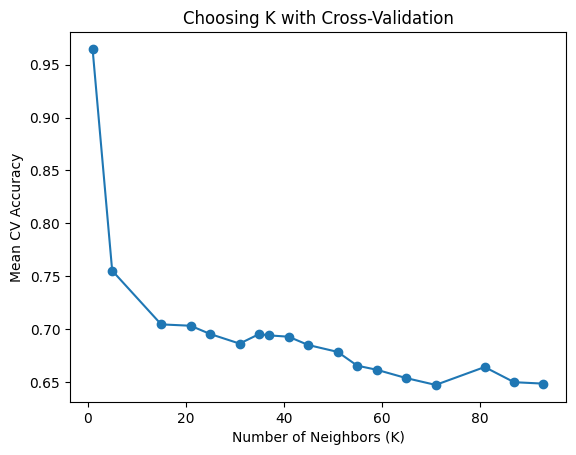

In [45]:
plt.plot(
    k_values,
    cv_scores,
    marker="o"
)

plt.xlabel("Number of Neighbors (K)")
plt.ylabel("Mean CV Accuracy")
plt.title("Choosing K with Cross-Validation")

plt.show()

The best K in the KNN is 1, which means there is something wrong with the dataset. Which could be the duplicates.

In [46]:
best_knn = make_pipeline(preprocess, KNeighborsClassifier(n_neighbors=best_k))
best_knn.fit(X_train, y_train)
knnpred = best_knn.predict(X_test)

In [47]:
accuracy_score(y_test, knnpred)

1.0

In [48]:
confusion_matrix(y_test, knnpred, labels=[0, 1])

array([[125,   0],
       [  0, 132]])

Looking at all of the models right now, KNN has the best accuracy so I will choose KNN. However later on it can change for a different model to be better.

**Part 4**

I will use the standard .50 threshold because the classes are nearly balanced and I will apply this threshold to all of the models.

**Logistic Regression**

In [49]:
pred50_labels = np.where(results["Prediction_0.50"] >= 0.50,
    "Yes",
    "No"
)


y_test_labels = np.where(y_test == 1, "Yes", "No")

confusion_matrix(
    results["Actual"],
    results["Prediction_0.50"])


array([[ 95,  30],
       [ 32, 100]])

In [50]:
TN, FP, FN, TP = cm.ravel()

print("TN:", TN)
print("FP:", FP)
print("FN:", FN)
print("TP:", TP)

TN: 95
FP: 30
FN: 32
TP: 100


In [51]:
accuracy = accuracy_score(
    y_test_labels,
    pred50_labels,
)
precision = precision_score(
    y_test_labels,
    pred50_labels,
    pos_label="Yes"
)
recall = recall_score(
    y_test_labels,
    pred50_labels,
    pos_label="Yes"
)
specificity = TN / (TN + FP)

f1 = f1_score(
    y_test_labels,
    pred50_labels,
    pos_label="Yes"
)



In [52]:
print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("Specificity:", specificity)
print("F1:", f1)

Accuracy: 0.7587548638132295
Precision: 0.7692307692307693
Recall: 0.7575757575757576
Specificity: 0.76
F1: 0.7633587786259542


**QDA**

In [53]:
confusion_matrix(y_test, qdapred, labels=[0, 1])

array([[ 70,  55],
       [ 27, 105]])

In [54]:
TN, FP, FN, TP = confusion_matrix(y_test, qdapred, labels=[0, 1]).ravel()
accuracy = accuracy_score(y_test, qdapred)
precision = precision_score(y_test, qdapred)
recall = recall_score(y_test, qdapred)
specificity = TN / (TN + FP)
f1 = f1_score(y_test, qdapred)



In [55]:

print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("Specificity:", specificity)
print("F1:", f1)



Accuracy: 0.6809338521400778
Precision: 0.65625
Recall: 0.7954545454545454
Specificity: 0.56
F1: 0.7191780821917808


**LDA**

In [56]:
confusion_matrix(y_test, ldapred, labels=[0, 1])

array([[ 97,  28],
       [ 26, 106]])

In [57]:
TN, FP, FN, TP = confusion_matrix(y_test, ldapred, labels=[0, 1]).ravel()
accuracy_score(y_test, ldapred)
precision = precision_score(y_test, ldapred)
recall = recall_score(y_test, ldapred)
specificity = TN / (TN + FP)
f1 = f1_score(y_test,ldapred)

In [58]:
print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("Specificity:", specificity)
print("F1:", f1)

Accuracy: 0.6809338521400778
Precision: 0.7910447761194029
Recall: 0.803030303030303
Specificity: 0.776
F1: 0.7969924812030075


**KNN**

In [59]:
confusion_matrix(y_test, knnpred, labels=[0, 1])

array([[125,   0],
       [  0, 132]])

In [60]:
TN, FP, FN, TP = confusion_matrix(y_test, knnpred, labels=[0, 1]).ravel()
accuracy_score(y_test, knnpred)
precision = precision_score(y_test, knnpred)
recall = recall_score(y_test, knnpred)
specificity = TN / (TN + FP)
f1 = f1_score(y_test,knnpred)

In [61]:
print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("Specificity:", specificity)
print("F1:", f1)

Accuracy: 0.6809338521400778
Precision: 1.0
Recall: 1.0
Specificity: 1.0
F1: 1.0


In [62]:
logreg_prob = logreg.predict_proba(X_test)[:, 1]
lda_prob    = lda.predict_proba(X_test)[:, 1]
qda_prob    = qda.predict_proba(X_test)[:, 1]
knn_prob    = best_knn.predict_proba(X_test)[:, 1]

In [63]:
print("Logistic Regression AUC:", roc_auc_score(y_test, logreg_prob))
print("LDA AUC:", roc_auc_score(y_test, lda_prob))
print("QDA AUC:", roc_auc_score(y_test, qda_prob))
print("KNN AUC:", roc_auc_score(y_test, knn_prob))

Logistic Regression AUC: 0.8696969696969696
LDA AUC: 0.8733333333333334
QDA AUC: 0.7346060606060607
KNN AUC: 1.0


In [64]:
logreg_cv = make_pipeline(preprocess, LogisticRegression(max_iter=5000))

logreg_grid = {
    'logisticregression__C': [0.001, 0.01, 0.1, 1, 10, 100]
}

grid_lr = GridSearchCV(
    logreg_cv,
    logreg_grid,
    cv=5,
    scoring='roc_auc'
)

grid_lr.fit(X_train, y_train)

lda_scores = cross_val_score(
    pipeline(LinearDiscriminantAnalysis()),
    X_train,
    y_train,
    cv=5,
    scoring='roc_auc'
)

grid_lr.fit(X_train, y_train)

lda_scores = cross_val_score(
    pipeline(LinearDiscriminantAnalysis()),
    X_train,
    y_train,
    cv=5,
    scoring='roc_auc'
)

qda_scores = cross_val_score(
    pipeline(QuadraticDiscriminantAnalysis()),
    X_train,
    y_train,
    cv=5,
    scoring='roc_auc'
)


/usr/local/lib/python3.13/dist-packages/sklearn/discriminant_analysis.py:1024: LinAlgWarning: The covariance matrix of class 0 is not full rank. Increasing the value of parameter `reg_param` might help reducing the collinearity.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/discriminant_analysis.py:1024: LinAlgWarning: The covariance matrix of class 1 is not full rank. Increasing the value of parameter `reg_param` might help reducing the collinearity.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/discriminant_analysis.py:1024: LinAlgWarning: The covariance matrix of class 0 is not full rank. Increasing the value of parameter `reg_param` might help reducing the collinearity.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/discriminant_analysis.py:1024: LinAlgWarning: The covariance matrix of class 1 is not full rank. Increasing the value of parameter `reg_param` might help reducing the collinearity.
  warnings.warn(
/usr/local/lib/p

In [65]:
print("KNN best parameters:", grid_knn.best_params_)
print("KNN best CV ROC-AUC:", round(grid_knn.best_score_, 4))

print("\nLogistic Regression best parameters:", grid_lr.best_params_)
print("Logistic Regression best CV ROC-AUC:", round(grid_lr.best_score_, 4))

print("\nLDA mean CV ROC-AUC:", round(lda_scores.mean(), 4))

print("QDA mean CV ROC-AUC:", round(qda_scores.mean(), 4))

KNN best parameters: {'kneighborsclassifier__n_neighbors': 51, 'kneighborsclassifier__weights': 'distance'}
KNN best CV ROC-AUC: 0.9981

Logistic Regression best parameters: {'logisticregression__C': 100}
Logistic Regression best CV ROC-AUC: 0.8699

LDA mean CV ROC-AUC: 0.8685
QDA mean CV ROC-AUC: 0.7836


**Part 5**

What I discovered is that at the default 0.50 threshold,LDA had an accuracy of .79, recall of.803, specificity of .776 and f1 of .797. Logistic Regression was accuracy 0.759, recall 0.758, specificity 0.760, and QDA is accuracy 0.681, specificity 0.560, recall .795.  KNN has the best precision, recall, specificity, F1 compared to all of the other models. However everything does come with a catch, with that being that there are 723 duplicate rows, so test patients likely have identical copies in the training data which is why we see that K=1. Recall (sensitivity) is the most important/informative metric as it tells us how many people that has heart disease that the model caught. Specificity and precision are still useful as they tell me how many false postives I have and how much negatives did I miss.

**Part 6**

In [66]:
auc = roc_auc_score(
    y_test,
    knn_prob
)
print("AUC:", auc)

AUC: 1.0


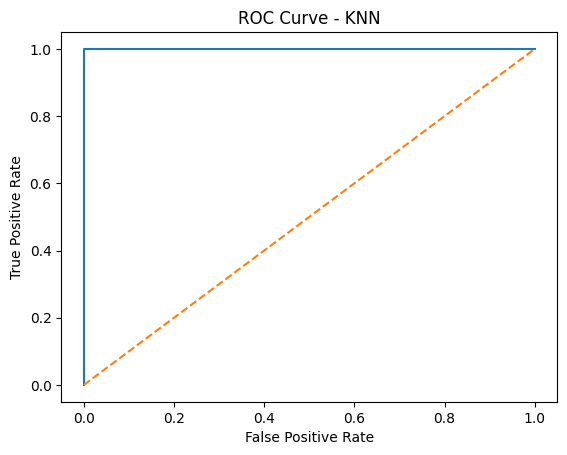

In [67]:
fpr, tpr, thresholds = roc_curve(
    y_test,
    knn_prob
)
plt.plot(
    fpr,
    tpr
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - KNN")

plt.show()

The roc curve for my KNN goes straight up and then to the right, and the curve shows the model’s true positive rate (recall) and false positive rate change. The dashed diagonal line is a model that guesses randomly, and the closer a curve gets to the top-left corner, the better the model separates patients with heart disease from patients without it. However this graph is bad because the issues that is in the dataset. That being there are 723 rows that are duplicate rows, so many test patients likely have identical copies in the training data. The AUC being 1 isn't good thing because it shouldn't be 1 and is the reason for said curve.

**Part 7**

1. The values that KNN is the best out of all four models(as everyything is 1), but it isn't trustworthy as the dataset has 723 duupilcate rows. K=1 isn't good as it is memorizing and not actually learning/doing anything. LDA is second as it has accuracy 0.790, recall 0.803, specificity 0.776, ROC-AUC 0.873). Logistic Regression is third (accuracy 0.759, recall 0.758, specificity 0.760, ROC-AUC 0.870). QDA is the worst (accuracy 0.681, specificity 0.560, ROC-AUC 0.735). So the most important difference is how flexible the models are, because KNN's is so flexibbility, it just memorize the duplicates. So it is overfit or overcleaned.
2. I would use either KNN or LDA because these two are the best for this dataset. KNN because it is perfect(but not for good reasons which is why I said LDA as well) and LDA because it deals with false negatives the best. So there are fewer sick patients since LDA has a better recall compared to the others.
3. The liimitation is the dataset ggiven, since 723 rows are duplicates. So there are really only ~300 real patients. There is really no way to tell which one is the real patients. This means the datatset is overcleaned.
4. A bigger dataset would be nice, withh there being more chinical measurements and me using more of them measurements for the models. I should also change the threshold iin the future and make sure the dataset doesn't have duplicates. Also use only useful variables because some of thhe currently variables given in the dataset or the future ones could be useless, so only the useful variables should be used.